# Pipeline A (graded applicant): interest-rate regression WITH the loan grade

| Setting | Known when deciding | PD model | Rate model |
|---|---|---|---|
| Reference: already-priced loan | rate + grade | notebooks 02–05 | none (rate already set) |
| **Pipeline A: graded applicant** | **grade only** | notebook 08 | **this notebook** |
| Pipeline B: newcomer | neither | notebook 06 | notebook 07 |

Notebook 07 priced a **newcomer** without `loan_grade` (R² ≈ 0.30). This notebook prices a **graded applicant**: the same models, but **the lender's grade (A–G) is also an input**, together with the PD from the graded-applicant PD model (notebook 08).

**When this pipeline is valid.** The grade is the lender's own risk rating and is set together with the rate. So this model answers *"given the lender's grade for this applicant, what rate fits?"*. That is realistic when the grade is **already known**: a lender that grades applicants first and then sets the rate within the grade, or checking existing loans. It **cannot** price a true newcomer who has no grade yet; that is notebook 07's job. A high R² here mostly shows how closely rates follow grades.

**Inputs.** The PD input is the **graded-applicant PD** from notebook 08 (details + grade, never the rate). The reference PD models (notebooks 02–05) used the interest rate itself, so feeding them in would leak the target.

| Input set | Inputs |
|---|---|
| grade only | `loan_grade` |
| grade + details | grade, age, income, employment length, home ownership, loan intent, loan amount, loan-to-income, past default, credit-history length |
| grade + details + PD | the above + graded-applicant PD (notebook 08) |

**Models (proposal):** Linear regression (baseline), Ridge, Lasso, Random Forest regressor. Same training loans, same 5 folds and the same metrics (RMSE, R², MAE) as notebook 07. The test set stays locked.

In [1]:
import sys, json, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import KFold, cross_validate, cross_val_predict, GridSearchCV, RandomizedSearchCV

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))
from src.credit import RANDOM_STATE, DATA, REPORTS, APPLICANT_NUM_COLS, APPLICANT_CAT_COLS, load_train, make_pipeline

X_train, _ = load_train()
pd_file = pd.read_csv(DATA / "oof_pd_graded.csv")          # same row order as train.csv
assert len(pd_file) == len(X_train)
data = X_train.copy()
data["graded_pd"] = pd_file["graded_pd"].values
data = data[data["loan_int_rate"].notna()].reset_index(drop=True)
y_rate = data["loan_int_rate"]
print(f"training loans with a known rate: {len(data):,}")

# How tightly does the rate follow the grade?
by_grade = data.groupby("loan_grade")["loan_int_rate"].agg(["count", "mean", "std", "min", "max"]).round(2)
display(by_grade)

FEATURES = {
    "grade only": ([], ["loan_grade"]),
    "grade + details": (APPLICANT_NUM_COLS, APPLICANT_CAT_COLS + ["loan_grade"]),
    "grade + details + PD": (["graded_pd"] + APPLICANT_NUM_COLS, APPLICANT_CAT_COLS + ["loan_grade"]),
}
kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)   # same folds as notebook 07
SCORING = {"RMSE": "neg_root_mean_squared_error", "MAE": "neg_mean_absolute_error", "R2": "r2"}

def pipe(model, feats):
    num, cat = FEATURES[feats]
    return make_pipeline(model, num_cols=num, cat_cols=cat)

def cv_scores(model, feats):
    r = cross_validate(pipe(model, feats), data, y_rate, cv=kf, scoring=SCORING, n_jobs=5)
    return {"RMSE": -r["test_RMSE"].mean(), "RMSE sd": r["test_RMSE"].std(),
            "MAE": -r["test_MAE"].mean(), "R2": r["test_R2"].mean()}

training loans with a known rate: 23,464


,count,mean,std,min,max
loan_grade,,,,,
A,7734,7.34,1.05,5.42,9.63
B,7449,10.99,0.91,6.00,12.69
C,4716,13.47,0.95,6.00,16.11
D,2642,15.37,1.12,6.00,18.49
E,698,17.01,1.35,6.00,20.30
F,174,18.62,1.36,15.01,21.74
G,51,20.27,1.00,18.36,23.22


## Step 1: Tune Ridge, Lasso and the Random Forest regressor

Same searches as notebook 07, on the richest input set (**grade + details + PD**): α for Ridge and Lasso by 5-fold CV (lowest mean RMSE), and a 10-combination randomized search for the forest.

Ridge: best alpha = 0.001 (CV RMSE 1.0076)
Lasso: best alpha = 0.0002154 (CV RMSE 1.0075)


Random Forest regressor: best {'min_samples_leaf': 1, 'max_features': 0.5, 'max_depth': 20} (CV RMSE 0.9989)
[302s]


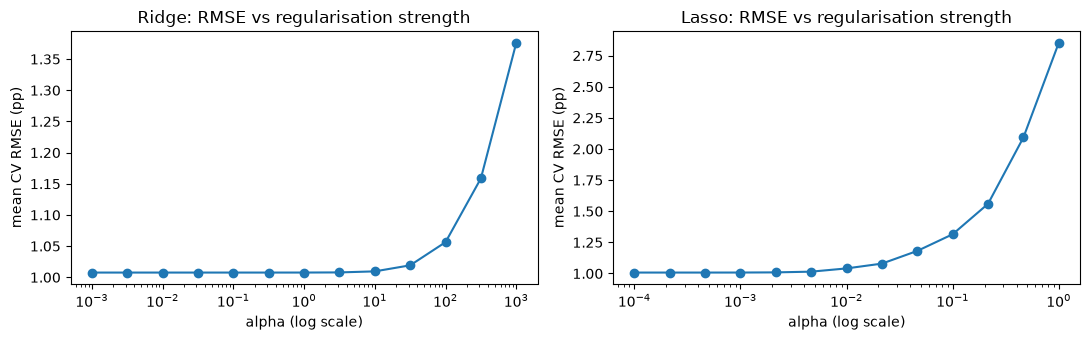

In [2]:
start = time.time()
FULL = "grade + details + PD"
ridge_gs = GridSearchCV(pipe(Ridge(), FULL), {"model__alpha": np.logspace(-3, 3, 13)},
                        cv=kf, scoring="neg_root_mean_squared_error", n_jobs=-1).fit(data, y_rate)
lasso_gs = GridSearchCV(pipe(Lasso(max_iter=20000), FULL), {"model__alpha": np.logspace(-4, 0, 13)},
                        cv=kf, scoring="neg_root_mean_squared_error", n_jobs=-1).fit(data, y_rate)
RIDGE_A, LASSO_A = ridge_gs.best_params_["model__alpha"], lasso_gs.best_params_["model__alpha"]
print(f"Ridge: best alpha = {RIDGE_A:.4g} (CV RMSE {-ridge_gs.best_score_:.4f})")
print(f"Lasso: best alpha = {LASSO_A:.4g} (CV RMSE {-lasso_gs.best_score_:.4f})")

rf_rs = RandomizedSearchCV(pipe(RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=1), FULL),
                           {"model__max_depth": [None, 10, 15, 20], "model__min_samples_leaf": [1, 5, 10, 20],
                            "model__max_features": ["sqrt", 0.5, None]},
                           n_iter=10, cv=kf, scoring="neg_root_mean_squared_error", n_jobs=-1,
                           random_state=RANDOM_STATE).fit(data, y_rate)
RF_P = {k.replace("model__", ""): v for k, v in rf_rs.best_params_.items()}
print(f"Random Forest regressor: best {RF_P} (CV RMSE {-rf_rs.best_score_:.4f})")
print(f"[{time.time() - start:.0f}s]")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, (name, gs) in zip(axes, [("Ridge", ridge_gs), ("Lasso", lasso_gs)]):
    res = pd.DataFrame(gs.cv_results_)
    ax.plot(res["param_model__alpha"].astype(float), -res["mean_test_score"], marker="o")
    ax.set_xscale("log"); ax.set_xlabel("alpha (log scale)"); ax.set_ylabel("mean CV RMSE (pp)")
    ax.set_title(f"{name}: RMSE vs regularisation strength")
plt.tight_layout(); plt.show()

## Step 2: Validation scores of every model and input set

5-fold CV. The bottom rows repeat notebook 07's best **newcomer** model (no grade) for comparison.

In [3]:
MODELS = {
    "Mean rate (no model)": DummyRegressor(strategy="mean"),
    "Linear regression": LinearRegression(),
    f"Ridge (alpha={RIDGE_A:.3g})": Ridge(alpha=RIDGE_A),
    f"Lasso (alpha={LASSO_A:.3g})": Lasso(alpha=LASSO_A, max_iter=20000),
    "Random Forest regressor": RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1, **RF_P),
}
rows = []
for feats in FEATURES:
    for name, model in MODELS.items():
        if name.startswith("Mean") and feats != FULL:
            continue
        rows.append({"inputs": feats, "model": name, **cv_scores(model, feats)})
results = pd.DataFrame(rows).set_index(["inputs", "model"])

nb07 = json.loads((REPORTS / "rate_model_choice.json").read_text())
results.loc[("NO grade: PD + details (notebook 07)", nb07["model"]), ["RMSE", "R2"]] = [nb07["cv_rmse"], nb07["cv_r2"]]
display(results.round(4))

RMSE  RMSE sd  \
inputs                               model                                      
grade only                           Linear regression        1.0092   0.0134   
                                     Ridge (alpha=0.001)      1.0092   0.0134   
                                     Lasso (alpha=0.000215)   1.0092   0.0134   
                                     Random Forest regressor  1.0092   0.0134   
grade + details                      Linear regression        1.0075   0.0134   
                                     Ridge (alpha=0.001)      1.0075   0.0134   
                                     Lasso (alpha=0.000215)   1.0075   0.0134   
                                     Random Forest regressor  0.9968   0.0143   
grade + details + PD                 Mean rate (no model)     3.2415   0.0148   
                                     Linear regression        1.0076   0.0134   
                                     Ridge (alpha=0.001)      1.0076   0.0134   
                                     Lasso (alpha=0.000215)   1.0075   0.0134   
                                     Random Forest regressor  0.9989   0.0141   
NO grade: PD + details (notebook 07) Random Forest regressor  2.7022      NaN   

                                                                 MAE      R2  
inputs                               model                                    
grade only                           Linear regression        0.7918  0.9030  
                                     Ridge (alpha=0.001)      0.7918  0.9030  
                                     Lasso (alpha=0.000215)   0.7916  0.9030  
                                     Random Forest regressor  0.7918  0.9030  
grade + details                      Linear regression        0.7915  0.9033  
                                     Ridge (alpha=0.001)      0.7915  0.9033  
                                     Lasso (alpha=0.000215)   0.7913  0.9033  
                                     Random Forest regressor  0.7833  0.9054  
grade + details + PD                 Mean rate (no model)     2.6941 -0.0002  
                                     Linear regression        0.7916  0.9033  
                                     Ridge (alpha=0.001)      0.7916  0.9033  
                                     Lasso (alpha=0.000215)   0.7914  0.9033  
                                     Random Forest regressor  0.7861  0.9050  
NO grade: PD + details (notebook 07) Random Forest regressor     NaN  0.3049

## Step 3: Choose the model and check it

**Choice:** lowest mean CV RMSE among the with-grade models. **Checks** on its out-of-fold predictions: predicted vs actual rate, the error within each grade, and the linear-model coefficients (how many percentage points each grade adds, and whether PD still matters once the grade is known).

chosen with-grade rate model: Random Forest regressor on 'grade + details' (CV RMSE 0.997 pp, R2 0.905)



Out-of-fold error within each grade:


,n,MAE,RMSE
grade,,,
A,7734,0.820,1.025
B,7449,0.746,0.906
C,4716,0.705,0.946
D,2642,0.846,1.109
E,698,0.981,1.315
F,174,1.073,1.419
G,51,0.830,1.067


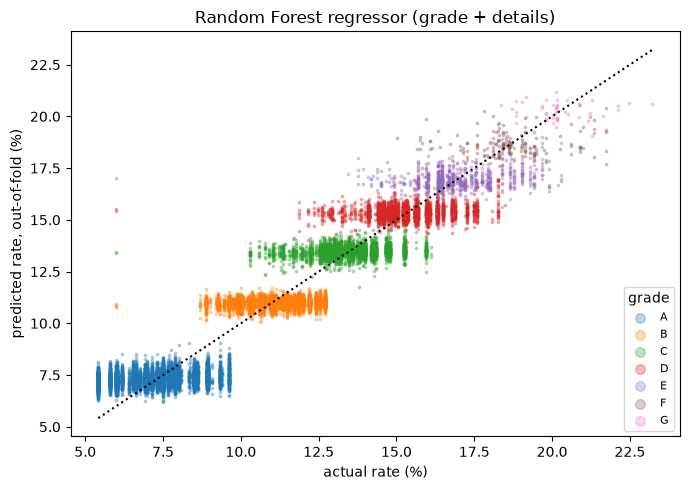

Linear-model coefficients on 'grade + details + PD' (pp of rate):


,Linear regression,Ridge (alpha=0.001),Lasso (alpha=0.000215)
graded_pd,0.001,0.001,0.002
person_age,-0.020,-0.020,-0.019
person_income,-0.019,-0.019,-0.018
person_emp_length,-0.012,-0.012,-0.012
loan_amnt,0.073,0.073,0.073
loan_percent_income,-0.042,-0.042,-0.042
cb_person_cred_hist_length,0.018,0.018,0.017
person_home_ownership_MORTGAGE,-0.131,-0.131,-0.122
person_home_ownership_OTHER,0.143,0.143,0.084
person_home_ownership_OWN,-0.003,-0.003,0.003


inputs Lasso dropped: ['loan_intent_DEBTCONSOLIDATION', 'loan_intent_EDUCATION', 'loan_intent_VENTURE', 'loan_grade_D']


In [4]:
with_grade = results.drop(index="Mean rate (no model)", level="model").loc[list(FEATURES)]
best_inputs, best_model = with_grade["RMSE"].idxmin()
print(f"chosen with-grade rate model: {best_model} on '{best_inputs}' "
      f"(CV RMSE {results.loc[(best_inputs, best_model), 'RMSE']:.3f} pp, R2 {results.loc[(best_inputs, best_model), 'R2']:.3f})")
rate_pipe = pipe(MODELS[best_model], best_inputs)
oof_rate = cross_val_predict(rate_pipe, data, y_rate, cv=kf, n_jobs=5)
err = oof_rate - y_rate

per_grade = (pd.DataFrame({"grade": data["loan_grade"], "abs err": err.abs(), "sq err": err ** 2})
               .groupby("grade").agg(n=("abs err", "size"), MAE=("abs err", "mean"), RMSE=("sq err", lambda s: np.sqrt(s.mean()))))
print("\nOut-of-fold error within each grade:")
display(per_grade.round(3))

fig, ax = plt.subplots(figsize=(7, 5))
for g, sub in data.assign(pred=oof_rate).groupby("loan_grade"):
    ax.scatter(sub["loan_int_rate"], sub["pred"], s=3, alpha=0.3, label=g)
lims = [y_rate.min(), y_rate.max()]
ax.plot(lims, lims, color="black", linestyle=":")
ax.set_xlabel("actual rate (%)"); ax.set_ylabel("predicted rate, out-of-fold (%)")
ax.set_title(f"{best_model} ({best_inputs})"); ax.legend(title="grade", markerscale=4, fontsize=8)
plt.tight_layout(); plt.show()

coef = {}
for name in [n for n in MODELS if n.startswith(("Linear", "Ridge", "Lasso"))]:
    p = pipe(MODELS[name], FULL).fit(data, y_rate)
    names = [n.replace("num__", "").replace("cat__", "") for n in p.named_steps["prep"].get_feature_names_out()]
    coef[name] = pd.Series(p.named_steps["model"].coef_, index=names)
coef = pd.DataFrame(coef)
print("Linear-model coefficients on 'grade + details + PD' (pp of rate):")
display(coef.round(3))
print("inputs Lasso dropped:", list(coef.index[coef.iloc[:, -1] == 0]) or "none")

In [5]:
choice = {"model": best_model, "inputs": best_inputs,
          "numeric": FEATURES[best_inputs][0], "categorical": FEATURES[best_inputs][1],
          "ridge_alpha": RIDGE_A, "lasso_alpha": LASSO_A, "rf_params": RF_P, "rf_n_estimators": 300,
          "cv_rmse": float(results.loc[(best_inputs, best_model), "RMSE"]),
          "cv_r2": float(results.loc[(best_inputs, best_model), "R2"]),
          "pipeline": "A (graded applicant)", "pd_input": "graded_pd (notebook 08)",
          "note": "requires the lender's loan_grade; not usable for newcomers without a grade"}
(REPORTS / "rate_model_with_grade_choice.json").write_text(json.dumps(choice, indent=2, default=str))
results.round(4).to_csv(REPORTS / "rate_model_with_grade_validation.csv")
print(json.dumps(choice, indent=2, default=str))

{
  "model": "Random Forest regressor",
  "inputs": "grade + details",
  "numeric": [
    "person_age",
    "person_income",
    "person_emp_length",
    "loan_amnt",
    "loan_percent_income",
    "cb_person_cred_hist_length"
  ],
  "categorical": [
    "person_home_ownership",
    "loan_intent",
    "cb_person_default_on_file",
    "loan_grade"
  ],
  "ridge_alpha": 0.001,
  "lasso_alpha": 0.00021544346900318845,
  "rf_params": {
    "min_samples_leaf": 1,
    "max_features": 0.5,
    "max_depth": 20
  },
  "rf_n_estimators": 300,
  "cv_rmse": 0.9967946434165345,
  "cv_r2": 0.9053795264870764,
  "pipeline": "A (graded applicant)",
  "pd_input": "graded_pd (notebook 08)",
  "note": "requires the lender's loan_grade; not usable for newcomers without a grade"
}
